<a href="https://colab.research.google.com/github/Anushka924403/learning_preprocessing/blob/main/Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**MODEL 1: LOGISTIC REGRESSION**


Logistic Regression is a supervised machine learning algorithm used for classification problems.

It predicts the probability that an input belongs to a particular class.

For example, in our Loan Approval dataset, we want to predict:
- 0 → Loan Rejected
- 1 → Loan Approved

Let's understand its working in 4 steps.

Step 1: Takes input features

The model takes numerical input features such as:
- Person age
- Income
- Credit score
- Loan amount
Step 2: Calculates a weighted sum

It multiplies each feature by its corresponding weight and adds them together.

Step 3: Applies the Sigmoid Function

This is the most important part of Logistic Regression.

The sigmoid function converts the calculated value into a probability between 0 and 1.

Step 4: Assigns a class

The default classification threshold is 0.5.

**Sigmoid Function
The sigmoid function is used to convert any real-valued number into a probability between 0 and 1.**

**Parameter	Purpose

C	Controls regularization strength.

penalty	Specifies the type of regularization.

solver	Algorithm used to optimize the model.

max_iter	Maximum number of iterations.

class_weight	Helps handle imbalanced classes.

random_state	Controls reproducibility where
applicable.**

In [ ]:
import os

# Display files available in the current directory
print(os.listdir())

['.config', 'loan_data.csv', 'sample_data']


In [ ]:
# Import pandas for data handling
import pandas as pd

# Import numpy for numerical operations
import numpy as np

# Import matplotlib for visualization
import matplotlib.pyplot as plt

# Import train_test_split to divide the dataset
from sklearn.model_selection import train_test_split

# Import Logistic Regression model
from sklearn.linear_model import LogisticRegression

# Import StandardScaler for feature scaling
from sklearn.preprocessing import StandardScaler

# Import evaluation metrics
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Load the loan approval dataset
df = pd.read_csv("loan_data.csv")

# Display first 5 rows
df.head()

# 1. Check number of rows and columns
print("Dataset Shape:", df.shape)

# 2. Check column names, data types and non-null values
df.info()

# 3. Check missing values in each column
print("\nMissing Values:")
print(df.isnull().sum())

# 4. Check duplicate records
print("\nDuplicate Rows:", df.duplicated().sum())

# 5. Display statistical information
df.describe()

# SEPRATING NUMERICAL AND CATEGORICAL COLUMNS
# Identify numerical columns
numerical_cols = df.select_dtypes(include=['int64', 'float64']).columns

# Identify categorical columns
categorical_cols = df.select_dtypes(include=['object']).columns

# Display numerical columns
print("Numerical Columns:")
print(list(numerical_cols))

# Display categorical columns
print("\nCategorical Columns:")
print(list(categorical_cols))




Dataset Shape: (45000, 14)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45000 entries, 0 to 44999
Data columns (total 14 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   person_age                      45000 non-null  float64
 1   person_gender                   45000 non-null  object 
 2   person_education                45000 non-null  object 
 3   person_income                   45000 non-null  float64
 4   person_emp_exp                  45000 non-null  int64  
 5   person_home_ownership           45000 non-null  object 
 6   loan_amnt                       45000 non-null  float64
 7   loan_intent                     45000 non-null  object 
 8   loan_int_rate                   45000 non-null  float64
 9   loan_percent_income             45000 non-null  float64
 10  cb_person_cred_hist_length      45000 non-null  float64
 11  credit_score                    45000 non-null  int64  
 12  previ

loan_status
0    35000
1    10000
Name: count, dtype: int64

Target Distribution (%):
loan_status
0    77.777778
1    22.222222
Name: proportion, dtype: float64


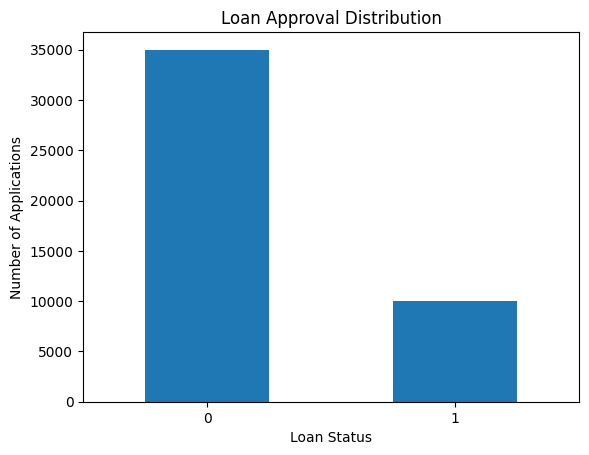

In [ ]:
# Check Target Variable Distribution
# Before training our model, we need to understand how many loans were approved and rejected.

# Our target variable is loan_status.
# Count the occurrences of each target class
print(df['loan_status'].value_counts())

# Calculate percentage distribution
print("\nTarget Distribution (%):")
print(df['loan_status'].value_counts(normalize=True) * 100)

# Visualize target distribution
df['loan_status'].value_counts().plot(
    kind='bar',
    title='Loan Approval Distribution'
)

plt.xlabel("Loan Status")
plt.ylabel("Number of Applications")
plt.xticks(rotation=0)
plt.show()

In [ ]:
# Step 6: Feature Selection (X and y)
# 1. X – Independent Variables (Input Features)
# These are the columns that the model uses to make predictions.
# 2. y – Dependent Variable (Target)
# This is the column we want our model to predict.

# Separate input features (X)
X = df.drop('loan_status', axis=1)
# we are using df.drop because except loan status we are storing everything in X

# Separate target variable (y)
y = df['loan_status']

# Display shapes
print("X Shape:", X.shape)
print("y Shape:", y.shape)

# Display first 5 rows of X
print("\nInput Features:")
print(X.head())

# Display first 5 values of y
print("\nTarget Variable:")
print(y.head())

X Shape: (45000, 13)
y Shape: (45000,)

Input Features:
   person_age person_gender person_education  person_income  person_emp_exp  \
0        22.0        female           Master        71948.0               0   
1        21.0        female      High School        12282.0               0   
2        25.0        female      High School        12438.0               3   
3        23.0        female         Bachelor        79753.0               0   
4        24.0          male           Master        66135.0               1   

  person_home_ownership  loan_amnt loan_intent  loan_int_rate  \
0                  RENT    35000.0    PERSONAL          16.02   
1                   OWN     1000.0   EDUCATION          11.14   
2              MORTGAGE     5500.0     MEDICAL          12.87   
3                  RENT    35000.0     MEDICAL          15.23   
4                  RENT    35000.0     MEDICAL          14.27   

   loan_percent_income  cb_person_cred_hist_length  credit_score  \
0         

In [ ]:
# Step 7: Train-Test Split
from sklearn.model_selection import train_test_split

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Display shapes
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)
# we are keeping 20% data for testing

X_train: (36000, 13)
X_test: (9000, 13)
y_train: (36000,)
y_test: (9000,)


In [ ]:
# Step 8: Categorical Encoding – One-Hot Encoding for gender coloumn
# Identify categorical columns
categorical_cols = X_train.select_dtypes(include=['object']).columns

# Apply One-Hot Encoding to training data
X_train_encoded = pd.get_dummies(
    X_train,
    columns=categorical_cols,
    drop_first=True,
    dtype=int
)

# Apply One-Hot Encoding to testing data
X_test_encoded = pd.get_dummies(
    X_test,
    columns=categorical_cols,
    drop_first=True,
    dtype=int
)

# Align testing columns with training columns
X_test_encoded = X_test_encoded.reindex(
    columns=X_train_encoded.columns,
    fill_value=0
)

# Display results
print("Before Encoding:", X_train.shape)
print("After Encoding:", X_train_encoded.shape)

print("\nEncoded Dataset:")
print(X_train_encoded.head())


Before Encoding: (36000, 13)
After Encoding: (36000, 22)

Encoded Dataset:
       person_age  person_income  person_emp_exp  loan_amnt  loan_int_rate  \
6048         24.0        58914.0               2     4400.0           5.99   
3346         23.0        45873.0               2    11000.0          11.01   
17998        29.0       240947.0               7    10000.0          12.69   
24988        30.0        96316.0              10     6000.0          13.49   
23231        29.0        73033.0               7     8000.0          10.51   

       loan_percent_income  cb_person_cred_hist_length  credit_score  \
6048                  0.07                         4.0           656   
3346                  0.24                         2.0           634   
17998                 0.04                         9.0           638   
24988                 0.06                         8.0           682   
23231                 0.11                         8.0           644   

       person_gender_ma

In [ ]:
# Step 9: Feature Scaling – StandardScaler
from sklearn.preprocessing import StandardScaler

# Identify numerical columns
numerical_cols = X_train_encoded.select_dtypes(
    include=['int64', 'float64']
).columns

# Create StandardScaler object
scaler = StandardScaler()

# Fit and transform training data
X_train_scaled = X_train_encoded.copy()

X_train_scaled[numerical_cols] = scaler.fit_transform(
    X_train_encoded[numerical_cols]
)

# Transform testing data using training statistics
X_test_scaled = X_test_encoded.copy()

X_test_scaled[numerical_cols] = scaler.transform(
    X_test_encoded[numerical_cols]
)

# Display results
print("Before Scaling:")
print(X_train_encoded[numerical_cols].head())

print("\nAfter Scaling:")
print(X_train_scaled[numerical_cols].head())

Before Scaling:
       person_age  person_income  person_emp_exp  loan_amnt  loan_int_rate  \
6048         24.0        58914.0               2     4400.0           5.99   
3346         23.0        45873.0               2    11000.0          11.01   
17998        29.0       240947.0               7    10000.0          12.69   
24988        30.0        96316.0              10     6000.0          13.49   
23231        29.0        73033.0               7     8000.0          10.51   

       loan_percent_income  cb_person_cred_hist_length  credit_score  \
6048                  0.07                         4.0           656   
3346                  0.24                         2.0           634   
17998                 0.04                         9.0           638   
24988                 0.06                         8.0           682   
23231                 0.11                         8.0           644   

       person_gender_male  person_education_Bachelor  ...  \
6048                 

In [ ]:
# Step 10: Train Logistic Regression Model
from sklearn.linear_model import LogisticRegression

# Create Logistic Regression model
model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train the model using training data
model.fit(X_train_scaled, y_train)

print("Logistic Regression Model Trained Successfully!")

In [ ]:
# Step 11: Make Predictions
# Predict loan approval status using testing data
y_pred = model.predict(X_test_scaled)

# Display first 10 actual and predicted values
print("Actual Values:")
print(y_test.head(10).values)

print("\nPredicted Values:")
print(y_pred[:10])

In [ ]:
# Step 12: Calculate Prediction Probability
# Calculate probability for each class
y_probability = model.predict_proba(X_test_scaled)

# Display first 10 probability predictions
print(y_probability[:10])

In [ ]:
# Step 13: Model Evaluation
from sklearn.metrics import accuracy_score

# Calculate model accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy * 100, "%")

from sklearn.metrics import confusion_matrix

# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

from sklearn.metrics import classification_report

# Generate classification report
print(classification_report(y_test, y_pred))

from sklearn.metrics import roc_auc_score, roc_curve
import matplotlib.pyplot as plt

# Calculate ROC-AUC score using class 1 probabilities
auc_score = roc_auc_score(y_test, y_probability[:, 1])

print("ROC-AUC Score:", auc_score)

# ROC-AUC measures how well the model distinguishes between two classes across different classification thresholds.

from sklearn.metrics import roc_auc_score, roc_curve
import matplotlib.pyplot as plt

# Calculate ROC-AUC score using class 1 probabilities
auc_score = roc_auc_score(y_test, y_probability[:, 1])

print("ROC-AUC Score:", auc_score)

# Calculate ROC curve values
fpr, tpr, thresholds = roc_curve(y_test, y_probability[:, 1])

# Plot ROC curve
plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {auc_score:.3f})")

# Plot random classifier reference line
plt.plot([0, 1], [0, 1], linestyle='--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()


In [ ]:
# Step 14: Predict a New Loan Application
# Create a new applicant record
new_applicant = pd.DataFrame([{
    'person_age': 25,
    'person_gender': 'male',
    'person_education': 'Bachelor',
    'person_income': 60000,
    'person_emp_exp': 2,
    'person_home_ownership': 'RENT',
    'loan_amnt': 10000,
    'loan_intent': 'PERSONAL',
    'loan_int_rate': 10.5,
    'loan_percent_income': 0.17,
    'cb_person_cred_hist_length': 4,
    'credit_score': 700,
    'previous_loan_defaults_on_file': 'No'
}])

# Apply the same One-Hot Encoding used during training
new_applicant_encoded = pd.get_dummies(
    new_applicant,
    columns=categorical_cols,
    drop_first=True,
    dtype=int
)

# Ensure the new applicant has the same columns as training data
new_applicant_encoded = new_applicant_encoded.reindex(
    columns=X_train_encoded.columns,
    fill_value=0
)

# Apply the previously fitted scaler
new_applicant_scaled = new_applicant_encoded.copy()

new_applicant_scaled[numerical_cols] = scaler.transform(
    new_applicant_encoded[numerical_cols]
)

# Predict loan status
prediction = model.predict(new_applicant_scaled)

# Calculate prediction probability
probability = model.predict_proba(new_applicant_scaled)

# Display result
if prediction[0] == 1:
    print("Loan Status: Approved")
else:
    print("Loan Status: Rejected")

print("Approval Probability:", probability[0][1] * 100, "%")


In [ ]:
# Step 15: Understand Model Coefficients
# Create a DataFrame containing feature names and coefficients
coefficients = pd.DataFrame({
    'Feature': X_train_scaled.columns,
    'Coefficient': model.coef_[0]
})

# Sort features by coefficient
coefficients = coefficients.sort_values(
    by='Coefficient',
    ascending=False
)

print(coefficients)

Three particularly important concepts from this practical:
1. model.fit() – Trains the model.
2. model.predict() – Predicts the class.
3. model.predict_proba() – Predicts the probability of each class.